# Formative 2: Modeling Human Activity States with Hidden Markov Models

Individual assignment. Smartphone accelerometer and gyroscope recordings (Sensor Logger) are used to decode four hidden
activity states, **Still, Standing, Walking, Jumping**, with a Gaussian-emission HMM implemented from scratch in `numpy`
(forward, backward, Viterbi, Baum-Welch). Only `numpy`, `pandas`, `scipy`, `matplotlib` and `seaborn` are used.

**Setup decisions (read first)**
* `Wraist_level` is waist-level **Standing**; `New_flat_surface` (recorded with the gravity channel on) is the **Still** training recording and replaces the earlier `Still_level` recording, which is not used.
* **Unseen test files:** `jumping_test_01` and `still_test_01` (recorded on a different phone, an iPhone 11 Pro). They are never used for training, scaling or tuning.
* `multi_test_01` is one continuous clip with all four activities. It is also held out, so every class has test windows. Its segment boundaries were read from the signal and confirmed by the author.
* **Leak fix:** `jumping_test_01` was recorded at the same moment as `jumping_train_01`. The overlapping part of the training clip is removed (see section 2).

In [1]:
import sys, json, copy, inspect
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO / "src"))
from data_utils import *
from features import *
from hmm import GaussianHMM, run_sanity_tests
SEED = 42; rng = np.random.default_rng(SEED); np.random.seed(SEED)
RAW, PROC, FIG = REPO / "data/raw", REPO / "data/processed", REPO / "figures"
PROC.mkdir(exist_ok=True); FIG.mkdir(exist_ok=True)
ACT = ["Still", "Standing", "Walking", "Jumping"]; K = len(ACT)
sns.set_theme(style="whitegrid", font_scale=0.9)
RES = {}   # numbers collected here are saved to figures/results.json and used by the report

## 1. Inventory and data-quality checks

In [2]:
REC = {"walking_train_01": ("Walking", "train"), "jumping_train_01": ("Jumping", "train"),
       "jumping_train_02": ("Jumping", "train"), "standing_train_01": ("Standing", "train"),
       "still_train_01": ("Still", "train"),
       "jumping_test_01": ("Jumping", "test"), "still_test_01": ("Still", "test"),
       "multi_test_01": ("Multi", "multi")}
man = pd.read_csv(REPO / "data/recordings_manifest.csv").set_index("recording")
rows, RAWD = [], {}
for rec, (lab, role) in REC.items():
    d = load_pair(RAW, rec); RAWD[rec] = d
    ta, Xa, _ = d["accelerometer"]; tg, Xg, _ = d["gyroscope"]
    rows.append(dict(recording=rec, label=lab, role=role, device=man.loc[rec, "device"],
                     duration_s=round(ta[-1] - ta[0], 1), native_hz=round(native_rate(ta), 1),
                     max_gap_s=round(np.diff(ta).max(), 3), nans=int(np.isnan(Xa).sum() + np.isnan(Xg).sum()),
                     same_length=len(ta) == len(tg), monotonic=bool((np.diff(ta) > 0).all())))
QC = pd.DataFrame(rows); QC.to_csv(REPO / "data/qc_table.csv", index=False); RES["qc"] = QC.to_dict("records")
QC

,recording,label,role,device,duration_s,native_hz,max_gap_s,nans,same_length,monotonic
0,walking_train_01,Walking,train,iPhone 11,121.5,100.1,0.01,0,True,True
1,jumping_train_01,Jumping,train,iPhone 11,60.0,100.1,0.01,0,True,True
2,jumping_train_02,Jumping,train,iPhone 11,49.6,100.1,0.01,0,True,True
3,standing_train_01,Standing,train,iPhone 11,122.1,100.1,0.01,0,True,True
4,still_train_01,Still,train,iPhone 11,122.1,100.1,0.01,0,True,True
5,jumping_test_01,Jumping,test,iPhone 11 Pro,25.9,99.8,0.01,0,True,True
6,still_test_01,Still,test,iPhone 11 Pro,122.3,99.8,0.01,0,True,True
7,multi_test_01,Multi,multi,iPhone 11,41.0,100.1,0.01,0,True,True


Notes on the data: Sensor Logger exports columns in the order `z, y, x`; the loader re-orders them to x, y, z. There are no NaNs, no
timestamp gaps larger than 0.01 s and no non-monotonic timestamps. The accelerometer is gravity-free (user acceleration in m/s²):
even the recording made with the gravity channel on keeps gravity in a separate `Gravity` file, which is not used as a model input.

## 2. Leakage check between the unseen jumping file and the training data

In [3]:
tt, _, ep_tr = RAWD["jumping_train_01"]["accelerometer"]; ts, _, ep_te = RAWD["jumping_test_01"]["accelerometer"]
lo, hi = max(ep_tr[0], ep_te[0]), min(ep_tr[-1], ep_te[-1])
overlap_s = (hi - lo) / 1e9
print(f"jumping_test_01 starts {(ep_te[0]-ep_tr[0])/1e9:.2f} s after jumping_train_01 and overlaps it for {overlap_s:.1f} s "
      f"(test clip length {(ep_te[-1]-ep_te[0])/1e9:.1f} s)")
# end of the overlap on the training clip's own clock (seconds_elapsed), plus a 1 s safety margin
LEAK_CUT = {"jumping_train_01": tt[0] + (ep_te[-1] - ep_tr[0]) / 1e9 + 1.0}
print("Training samples of jumping_train_01 before raw t =", round(LEAK_CUT["jumping_train_01"], 2), "s are removed.")
RES["leak_overlap_s"] = round(overlap_s, 1); RES["leak_cut_s"] = round(LEAK_CUT["jumping_train_01"], 1)

jumping_test_01 starts 0.47 s after jumping_train_01 and overlaps it for 25.9 s (test clip length 25.9 s)
Training samples of jumping_train_01 before raw t = 27.41 s are removed.


## 3. Pre-processing: harmonise sampling rate, trim, chunk
* **Common rate: 50 Hz.** Native rates are about 100.1 Hz (iPhone 11) and 99.8 Hz (iPhone 11 Pro). Each signal is linearly interpolated onto an exact 100 Hz grid, low-pass filtered (zero-phase FIR anti-alias filter) and decimated by 2. 50 Hz keeps content up to 25 Hz, far above walking and jumping cycles (about 1-4 Hz), and halves the cost.
* **Trim:** 3 s are removed at both ends of every clip (phone handling and settling).
* **Chunks:** each trimmed recording is split into non-overlapping 10 s chunks (remainders under 5 s are dropped). Windows are cut *inside* chunks, so a window never crosses a chunk border, and all chunks of a recording stay on the same side of the train/test split.

In [4]:
P, chunk_rows = {}, []
for rec, (lab, role) in REC.items():
    (ta, Xa, _), (tg, Xg, _) = RAWD[rec]["accelerometer"], RAWD[rec]["gyroscope"]
    fs = native_rate(ta)
    t1, A = harmonise(ta, Xa, fs); t2, G = harmonise(tg, Xg, fs)
    n = min(len(t1), len(t2)); t, A, G = t1[:n], A[:n], G[:n]
    tk, A = trim(t, A); _, G = trim(t, G); t = tk
    if rec in LEAK_CUT:
        k = t >= LEAK_CUT[rec]; t, A, G = t[k], A[k], G[k]
    df = pd.DataFrame(np.column_stack([t - t[0], t, A, G]), columns=["t", "t_raw", "ax", "ay", "az", "gx", "gy", "gz"])
    df["chunk"] = -1
    for c, (a, b) in enumerate(make_chunks(len(df), TARGET_FS)):
        df.loc[a:b - 1, "chunk"] = c
        chunk_rows.append(dict(recording=rec, label=lab, role=role, chunk=c, seconds=(b - a) / TARGET_FS))
    df.to_csv(PROC / f"{rec}_50hz.csv", index=False); P[rec] = df
CH = pd.DataFrame(chunk_rows); CH.to_csv(REPO / "data/chunk_table.csv", index=False)
RATES = QC.groupby("device").native_hz.agg(["min", "max"]).round(1)
print("Original rates:\n", RATES, f"\n-> all resampled to {TARGET_FS} Hz")
CH.groupby(["role", "label"]).agg(chunks=("chunk", "count"), seconds=("seconds", "sum")).round(1)

Original rates:
                  min    max
device                     
iPhone 11      100.1  100.1
iPhone 11 Pro   99.8   99.8 
-> all resampled to 50 Hz


chunks  seconds
role  label                    
multi Multi          4     35.0
test  Jumping        2     19.8
      Still         12    116.3
train Jumping        7     69.7
      Standing      12    116.1
      Still         12    116.1
      Walking       12    115.5

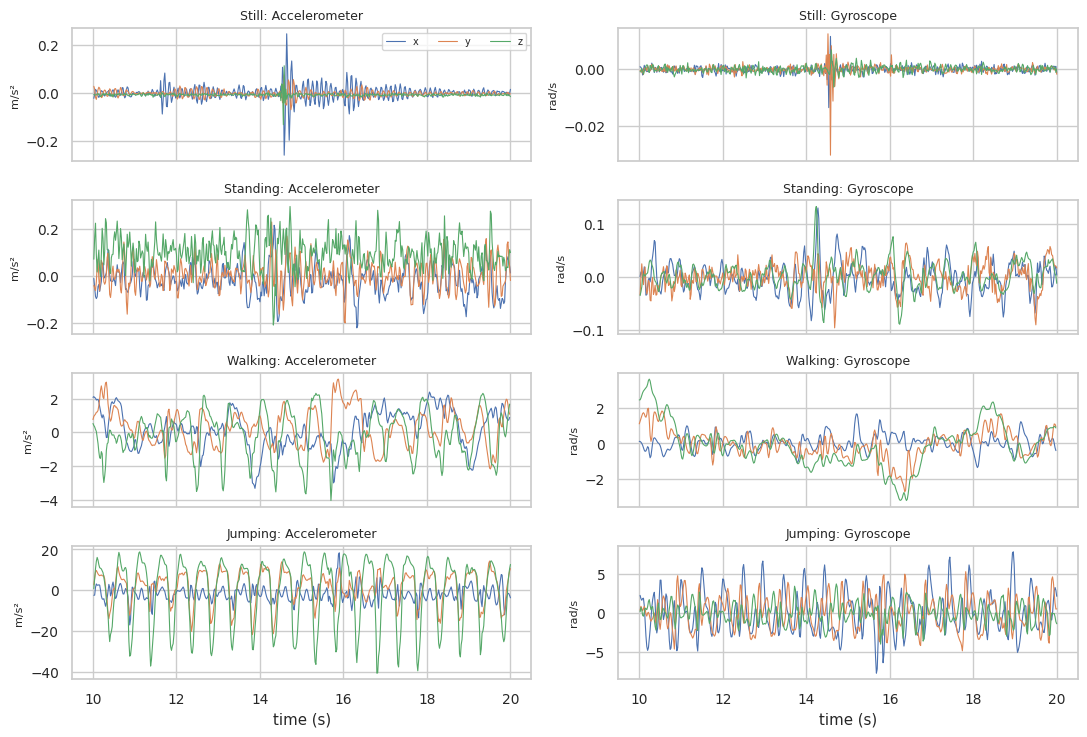

In [5]:
acts = [("Still", "still_train_01"), ("Standing", "standing_train_01"), ("Walking", "walking_train_01"), ("Jumping", "jumping_train_01")]
fig, axs = plt.subplots(4, 2, figsize=(11, 7.5), sharex=True)
for r, (lab, nm) in enumerate(acts):
    seg = P[nm][(P[nm].t >= 10) & (P[nm].t < 20)]
    for c, (cols, ttl, u) in enumerate([(["ax", "ay", "az"], "Accelerometer", "m/s²"), (["gx", "gy", "gz"], "Gyroscope", "rad/s")]):
        for k in cols: axs[r, c].plot(seg.t, seg[k], lw=.8, label=k[-1])
        axs[r, c].set_title(f"{lab}: {ttl}", fontsize=9); axs[r, c].set_ylabel(u, fontsize=8)
axs[0, 0].legend(ncol=3, fontsize=7); axs[3, 0].set_xlabel("time (s)"); axs[3, 1].set_xlabel("time (s)")
plt.tight_layout(); plt.savefig(FIG / "raw_signals.png", dpi=150); plt.show()

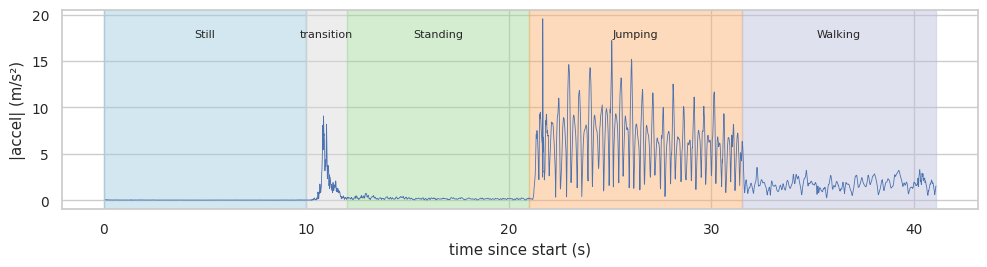

In [6]:
# Multi-activity clip with the confirmed segment boundaries (raw recording clock)
SEGS = [(0, 10, "Still"), (10, 12, "transition"), (12, 21, "Standing"), (21, 31.5, "Jumping"), (31.5, 1e9, "Walking")]
ta, Xa, _ = RAWD["multi_test_01"]["accelerometer"]; mag = np.linalg.norm(Xa, axis=1)
fig, ax = plt.subplots(figsize=(10, 2.8)); ax.plot(ta, mag, lw=.6); ax.set_ylabel("|accel| (m/s²)"); ax.set_xlabel("time since start (s)")
colr = {"Still": "#9ecae1", "transition": "#d9d9d9", "Standing": "#a1d99b", "Jumping": "#fdae6b", "Walking": "#bcbddc"}
for a, b, l in SEGS:
    b = min(b, ta[-1]); ax.axvspan(a, b, color=colr[l], alpha=.45); ax.text((a + b) / 2, mag.max() * .9, l, ha="center", fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "multi_activity_overview.png", dpi=150); plt.show()

## 4. Windowing and feature extraction
**Window = 2 s (100 samples at 50 Hz), 50 % overlap.** Walking and jumping repeat at roughly 1.5-4 Hz, so 2 s contains several cycles (about 3-8)
and the FFT resolution is 0.5 Hz, while the temporal resolution stays fine enough to follow activity changes. Each window takes the label of
its source recording; windows of the multi-activity clip are labelled by the segment containing the window centre, and windows touching the 10-12 s
pick-up transition are marked `transition` (decoded, but not scored).

**Features (8 per sensor, 16 in total)**: time-domain: mean of magnitude, variance, RMS, signal magnitude area (SMA), mean absolute inter-axis correlation;
frequency-domain (FFT of the detrended, Hann-windowed magnitude): dominant frequency, spectral energy, normalised spectral entropy.

In [7]:
tabs = []
for rec, (lab, role) in REC.items():
    F = recording_windows(P[rec], chunk_aware=(role == "train")); F["recording"], F["role"], F["label"] = rec, role, lab; tabs.append(F)
W = pd.concat(tabs, ignore_index=True)
m = W.recording == "multi_test_01"
ctr = (W.loc[m, "t_raw_start"] + W.loc[m, "t_raw_end"]) / 2
W.loc[m, "label"] = [next(l for a, b, l in SEGS if a <= t < b) for t in ctr]
touch = (W.loc[m, "t_raw_start"] < 12) & (W.loc[m, "t_raw_end"] > 10)
W.loc[m, "label"] = np.where(touch, "transition", W.loc[m, "label"])
W["split"] = W.role.map({"train": "train", "test": "test_unseen", "multi": "test_multi"})
WC = W.groupby(["split", "label"]).size().unstack(fill_value=0); RES["window_counts"] = WC.to_dict("index"); WC

label,Jumping,Standing,Still,Walking,transition
split,,,,,
test_multi,11,8,5,6,4
test_unseen,18,0,115,0,0
train,62,104,104,103,0


**Normalisation.** Variance, RMS, SMA and spectral energy span 4-6 orders of magnitude between Still and Jumping, which a Gaussian emission cannot represent well, so these four features are
log10-transformed first. All features are then **Z-scored with a scaler fitted on training windows only** and applied unchanged to the test files; fitting on test data would leak the test
distribution into training. Z-scoring puts all features on one scale so that no single feature dominates the diagonal Gaussians.

train mean |max|: 0.0 | train std: [1.]


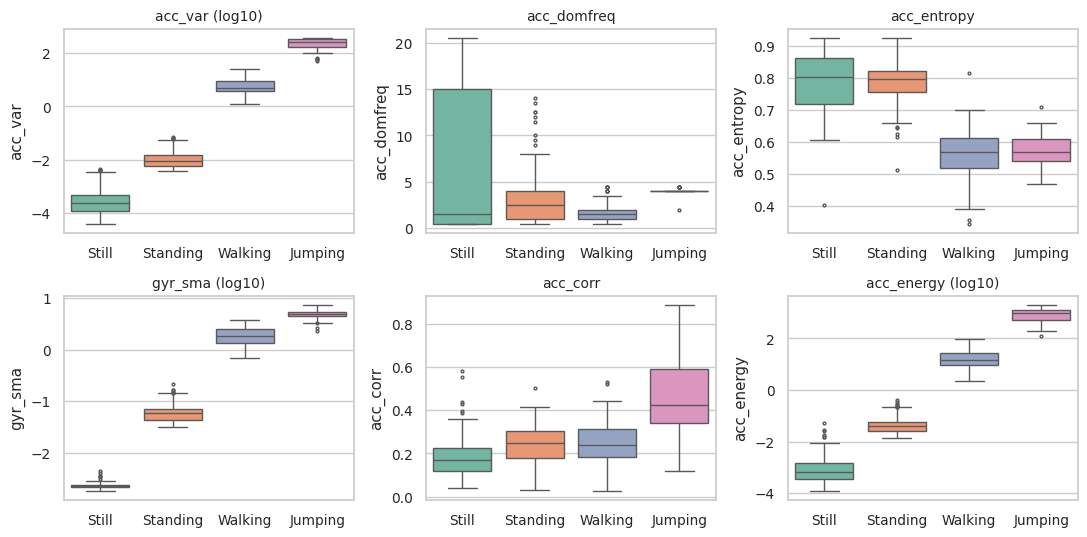

In [8]:
X = transform_features(W); trm = (W.split == "train").to_numpy()
sc = ZScaler().fit(X[trm]); Z = pd.DataFrame(sc.transform(X), columns=FEATURE_NAMES)
print("train mean |max|:", np.abs(Z[trm].mean()).max().round(8), "| train std:", Z[trm].std(ddof=0).round(3).unique())
Zall = pd.concat([W[["recording", "split", "label", "chunk", "t_start", "t_end"]], Z], axis=1)
Zall.to_csv(REPO / "data/features_zscored.csv", index=False); W.to_csv(REPO / "data/features_raw.csv", index=False)
order = ["Still", "Standing", "Walking", "Jumping"]
Tr = X[trm].assign(label=W.loc[trm, "label"].values)
fig, axs = plt.subplots(2, 3, figsize=(11, 5.5))
for ax, f in zip(axs.ravel(), ["acc_var", "acc_domfreq", "acc_entropy", "gyr_sma", "acc_corr", "acc_energy"]):
    sns.boxplot(data=Tr, x="label", y=f, order=order, hue="label", hue_order=order, palette="Set2", legend=False, fliersize=2, ax=ax)
    ax.set_title(f + (" (log10)" if f.split("_", 1)[1] in LOG_FEATS else ""), fontsize=10); ax.set_xlabel("")
plt.tight_layout(); plt.savefig(FIG / "feature_boxplots.png", dpi=150); plt.show()

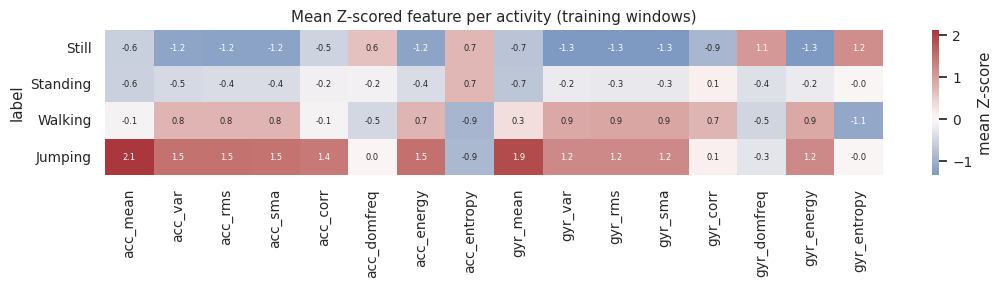

           acc_var  acc_domfreq  acc_entropy  gyr_sma
label                                                
Still       0.0002          1.5       0.8024   0.0022
Standing    0.0091          2.5       0.7967   0.0590
Walking     5.0708          1.5       0.5690   1.8806
Jumping   255.2110          4.0       0.5698   4.8597


In [9]:
Zt = Z[trm].assign(label=W.loc[trm, "label"].values).groupby("label").mean().loc[order]
plt.figure(figsize=(11, 3)); sns.heatmap(Zt, cmap="vlag", center=0, annot=True, fmt=".1f", annot_kws={"size": 6}, cbar_kws={"label": "mean Z-score"})
plt.title("Mean Z-scored feature per activity (training windows)"); plt.tight_layout(); plt.savefig(FIG / "feature_means_heatmap.png", dpi=150); plt.show()
print(W[trm].groupby("label")[["acc_var", "acc_domfreq", "acc_entropy", "gyr_sma"]].median().loc[order].round(4))
RES["median_feats"] = W[trm].groupby("label")[["acc_var", "acc_domfreq", "acc_entropy", "gyr_sma"]].median().loc[order].round(4).to_dict("index")

Why the features separate the activities: variance, RMS and SMA grow with movement intensity (Still < Standing < Walking < Jumping, boxplot above);
dominant frequency separates the rhythmic activities (walking steps at about 1-2 Hz, jumps at about 4 Hz) from the noise-like Still and Standing windows;
spectral entropy is high for broadband noise (Still, Standing) and lower for periodic motion (Walking, Jumping); the gyroscope SMA captures body rotation, which is small when the phone is held
steady and large for jumping; axis correlation indicates whether motion is concentrated along one direction.

## 5. HMM from scratch (`src/hmm.py`)
`GaussianHMM` implements log-space **forward** and **backward** passes, **Viterbi** decoding, and **Baum-Welch** over multiple sequences with a log-likelihood convergence check
(stop when the change is below 1e-4, safety cap 200 iterations). Emissions are Gaussians with diagonal covariance and a variance floor of 0.01 (Z-score units); a small floor (1e-3) smooths transition counts.

**Supervised vs unsupervised.** π, A, emission means and variances are first initialised from the *labelled* training sequences (supervised). Baum-Welch then re-estimates them from the
observations only, ignoring labels (unsupervised refinement).

In [10]:
print(run_sanity_tests())
print(inspect.getsource(GaussianHMM.viterbi))

all sanity tests passed
    def viterbi(self, X):
        """Most likely state sequence (log-space). Returns (path, log-prob of path)."""
        logB = self.log_emission(X); T, K = logB.shape; lA = _log(self.A)
        delta = np.empty((T, K)); psi = np.zeros((T, K), int)
        delta[0] = _log(self.pi) + logB[0]
        for t in range(1, T):
            cand = delta[t - 1][:, None] + lA
            psi[t] = cand.argmax(0); delta[t] = cand.max(0) + logB[t]
        path = np.empty(T, int); path[-1] = delta[-1].argmax()
        for t in range(T - 2, -1, -1):
            path[t] = psi[t + 1, path[t + 1]]
        return path, delta[-1].max()



### Training sequences
No training recording contains more than one activity, so a transition matrix estimated from single recordings would be near-identity and meaningless. Instead, **40 training sequences** are built
by concatenating eight 10 s training chunks in random order, with the activity of each chunk different from the one before (seeded). The off-diagonal transition mass is therefore **a consequence of
this construction** (each chunk is 9 windows long, so a switch happens every 9 windows on average), not a measurement of real behaviour.

In [11]:
tr = Zall[Zall.split == "train"]
pools = {a: [g for _, g in tr[tr.label == a].groupby(["recording", "chunk"])] for a in ACT}
cyc = {a: list(rng.permutation(len(pools[a]))) for a in ACT}
def next_chunk(a):
    if not cyc[a]: cyc[a] = list(rng.permutation(len(pools[a])))
    return pools[a][cyc[a].pop()]
N_SEQ, CH_PER_SEQ = 40, 8
seqs, labs = [], []
for _ in range(N_SEQ):
    prev, Xs, ys = None, [], []
    for _ in range(CH_PER_SEQ):
        a = rng.choice([x for x in ACT if x != prev]); prev = a; g = next_chunk(a)
        Xs.append(g[FEATURE_NAMES].to_numpy()); ys.append(np.full(len(g), ACT.index(a)))
    seqs.append(np.vstack(Xs)); labs.append(np.concatenate(ys))
print(N_SEQ, "sequences,", sum(map(len, seqs)), "windows; chunks available per class:", {a: len(pools[a]) for a in ACT})
sup = GaussianHMM(K).init_supervised(seqs, labs)          # supervised initialisation
bw = copy.deepcopy(sup); hist = bw.baum_welch(seqs, max_iter=200, tol=1e-4)   # unsupervised refinement
assert np.allclose(bw.A.sum(1), 1) and (np.diff(hist) >= -1e-6).all()
print(f"Baum-Welch: {bw.n_iter_} iterations, log-likelihood {hist[0]:.2f} -> {hist[-1]:.2f}, last change {abs(hist[-1]-hist[-2]):.1e}")
RES.update(n_seq=N_SEQ, seq_windows=int(sum(map(len, seqs))), bw_iters=int(bw.n_iter_), ll_first=float(hist[0]), ll_last=float(hist[-1]),
           ll_change=float(abs(hist[-1] - hist[-2])), A=bw.A.tolist(), A_init=sup.A.tolist(), pi=bw.pi.tolist(), chunks={a: len(pools[a]) for a in ACT})
pd.DataFrame(bw.A, ACT, ACT).round(3)

40 sequences, 2780 windows; chunks available per class: {'Still': 12, 'Standing': 12, 'Walking': 12, 'Jumping': 7}


Baum-Welch: 2 iterations, log-likelihood 4840.05 -> 4840.05, last change 1.1e-08


,Still,Standing,Walking,Jumping
Still,0.897,0.037,0.040,0.026
Standing,0.024,0.899,0.037,0.040
Walking,0.021,0.033,0.894,0.052
Jumping,0.042,0.030,0.028,0.901


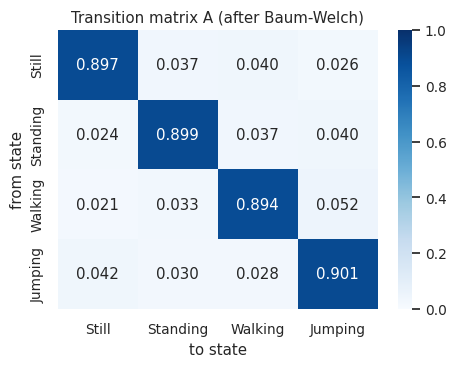

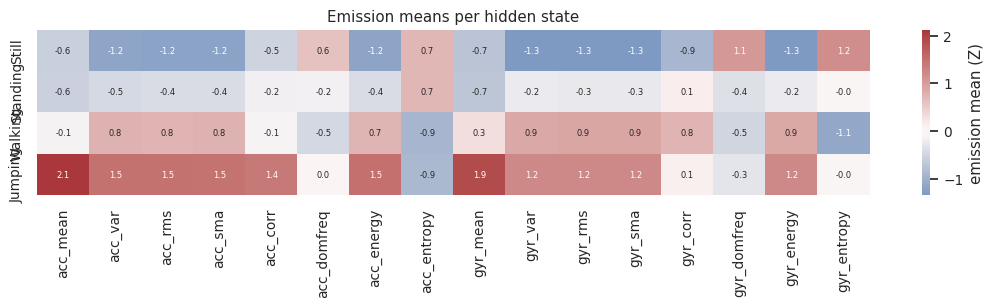

In [12]:
plt.figure(figsize=(4.8, 3.8)); sns.heatmap(bw.A, annot=True, fmt=".3f", cmap="Blues", xticklabels=ACT, yticklabels=ACT, vmin=0, vmax=1)
plt.xlabel("to state"); plt.ylabel("from state"); plt.title("Transition matrix A (after Baum-Welch)"); plt.tight_layout(); plt.savefig(FIG / "transition_matrix.png", dpi=150); plt.show()
plt.figure(figsize=(11, 3.2)); sns.heatmap(pd.DataFrame(bw.mu, ACT, FEATURE_NAMES), cmap="vlag", center=0, annot=True, fmt=".1f", annot_kws={"size": 6}, cbar_kws={"label": "emission mean (Z)"})
plt.title("Emission means per hidden state"); plt.tight_layout(); plt.savefig(FIG / "emission_means.png", dpi=150); plt.show()

## 6. Evaluation on unseen data
Each held-out recording is decoded with Viterbi as its own sequence. The metrics are one-vs-rest, derived from the confusion matrix. Windows of the pick-up transition in the multi-activity
clip are decoded but excluded from scoring. The **required two unseen files** contain only Still and Jumping, so Walking and Standing have no test windows there (sensitivity undefined);
the multi-activity clip supplies them.

In [13]:
held = {n: Zall[Zall.recording == n].sort_values("t_start").reset_index(drop=True) for n in ["jumping_test_01", "still_test_01", "multi_test_01"]}
def metrics(yt, yp):
    cm = np.zeros((K, K), int); np.add.at(cm, (yt, yp), 1); N = cm.sum(); rows = []
    for k in range(K):
        TP = cm[k, k]; FN = cm[k].sum() - TP; FP = cm[:, k].sum() - TP; TN = N - TP - FN - FP
        rows.append({"Activity": ACT[k], "Samples": int(cm[k].sum()), "Sensitivity": TP / (TP + FN) if TP + FN else np.nan,
                     "Specificity": TN / (TN + FP) if TN + FP else np.nan, "Accuracy (one-vs-rest)": (TP + TN) / N})
    return cm, pd.DataFrame(rows), np.trace(cm) / N
def evaluate(model, names, framewise=False, mapping=None):
    yt, yp, per = [], [], {}
    for n in names:
        Xn = held[n][FEATURE_NAMES].to_numpy()
        path = model.log_emission(Xn).argmax(1) if framewise else model.viterbi(Xn)[0]
        if mapping is not None: path = np.asarray(mapping)[path]
        lab = held[n].label.to_numpy(); keep = lab != "transition"
        t = np.array([ACT.index(l) for l in lab[keep]]); p = path[keep]; yt.append(t); yp.append(p); per[n] = float((t == p).mean())
        held[n]["pred"] = [ACT[i] for i in path]
    return metrics(np.concatenate(yt), np.concatenate(yp)) + (per,)
SETS = {"2 unseen files": ["jumping_test_01", "still_test_01"], "2 unseen + multi-activity": ["jumping_test_01", "still_test_01", "multi_test_01"], "multi-activity only": ["multi_test_01"]}
out = {}
for tag, mdl, fw in [("Viterbi + Baum-Welch (main)", bw, False), ("Viterbi, supervised init only", sup, False), ("Frame-wise Gaussian (no transitions)", bw, True)]:
    for sname, names in SETS.items(): out[(tag, sname)] = evaluate(mdl, names, fw)
main = "Viterbi + Baum-Welch (main)"
for sname in SETS:
    cm, tab, acc, per = out[(main, sname)]
    print(f"\n### {sname}: overall accuracy {acc:.3f}; per-file accuracy {({k: round(v, 3) for k, v in per.items()})}")
    display(tab.round(3)); display(pd.DataFrame(cm, ACT, ACT))
evaluate(bw, SETS["2 unseen + multi-activity"])      # leaves the main model's predictions in `held` for plotting


### 2 unseen files: overall accuracy 0.962; per-file accuracy {'jumping_test_01': 1.0, 'still_test_01': 0.957}


,Activity,Samples,Sensitivity,Specificity,Accuracy (one-vs-rest)
0,Still,115,0.957,1.000,0.962
1,Standing,0,NaN,0.962,0.962
2,Walking,0,NaN,1.000,1.000
3,Jumping,18,1.000,1.000,1.000


,Still,Standing,Walking,Jumping
Still,110,5,0,0
Standing,0,0,0,0
Walking,0,0,0,0
Jumping,0,0,0,18



### 2 unseen + multi-activity: overall accuracy 0.920; per-file accuracy {'jumping_test_01': 1.0, 'still_test_01': 0.957, 'multi_test_01': 0.733}


,Activity,Samples,Sensitivity,Specificity,Accuracy (one-vs-rest)
0,Still,120,0.958,1.000,0.969
1,Standing,8,1.000,0.968,0.969
2,Walking,6,1.000,0.949,0.951
3,Jumping,29,0.724,1.000,0.951


,Still,Standing,Walking,Jumping
Still,115,5,0,0
Standing,0,8,0,0
Walking,0,0,6,0
Jumping,0,0,8,21



### multi-activity only: overall accuracy 0.733; per-file accuracy {'multi_test_01': 0.733}


,Activity,Samples,Sensitivity,Specificity,Accuracy (one-vs-rest)
0,Still,5,1.000,1.000,1.000
1,Standing,8,1.000,1.000,1.000
2,Walking,6,1.000,0.667,0.733
3,Jumping,11,0.273,1.000,0.733


,Still,Standing,Walking,Jumping
Still,5,0,0,0
Standing,0,8,0,0
Walking,0,0,6,0
Jumping,0,0,8,3


(array([[115,   5,   0,   0],
        [  0,   8,   0,   0],
        [  0,   0,   6,   0],
        [  0,   0,   8,  21]]),
    Activity  Samples  Sensitivity  Specificity  Accuracy (one-vs-rest)
 0     Still      120     0.958333     1.000000                0.969325
 1  Standing        8     1.000000     0.967742                0.969325
 2   Walking        6     1.000000     0.949045                0.950920
 3   Jumping       29     0.724138     1.000000                0.950920,
 np.float64(0.9202453987730062),
 {'jumping_test_01': 1.0,
  'still_test_01': 0.9565217391304348,
  'multi_test_01': 0.7333333333333333})

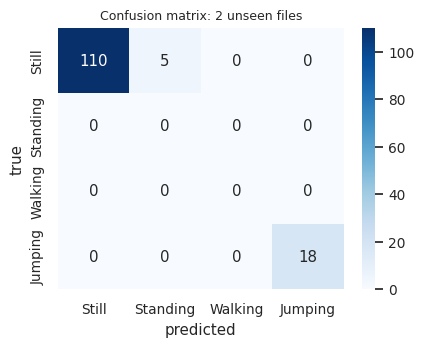

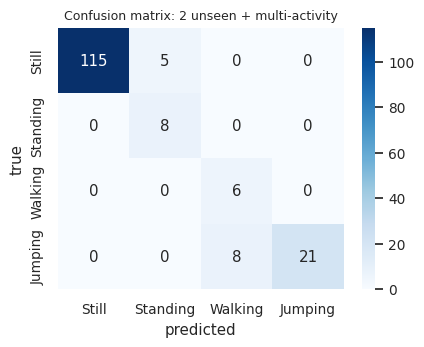

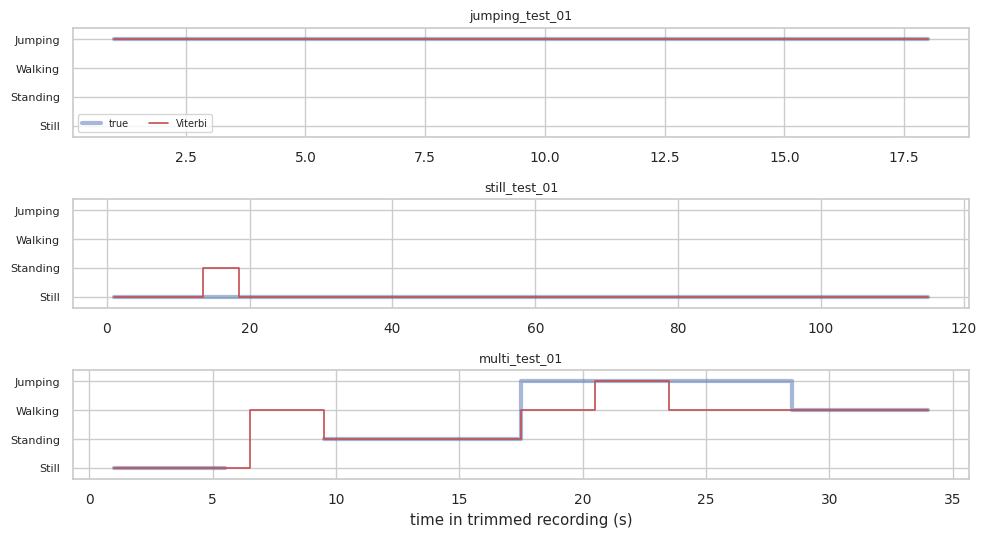

In [14]:
for nm, key in [("confusion_matrix_unseen2", "2 unseen files"), ("confusion_matrix_heldout", "2 unseen + multi-activity")]:
    plt.figure(figsize=(4.4, 3.6)); sns.heatmap(out[(main, key)][0], annot=True, fmt="d", cmap="Blues", xticklabels=ACT, yticklabels=ACT)
    plt.xlabel("predicted"); plt.ylabel("true"); plt.title(f"Confusion matrix: {key}", fontsize=9); plt.tight_layout(); plt.savefig(FIG / f"{nm}.png", dpi=150); plt.show()
fig, axs = plt.subplots(3, 1, figsize=(10, 5.5))
for ax, n in zip(axs, held):
    g = held[n]; t = (g.t_start + g.t_end) / 2
    ax.step(t, [ACT.index(l) if l != "transition" else np.nan for l in g.label], where="mid", lw=3, alpha=.5, label="true")
    ax.step(t, [ACT.index(l) for l in g.pred], where="mid", lw=1.2, color="C3", label="Viterbi")
    ax.set_yticks(range(K)); ax.set_yticklabels(ACT, fontsize=8); ax.set_ylim(-.4, 3.4); ax.set_title(n, fontsize=9)
axs[0].legend(ncol=2, fontsize=7); axs[2].set_xlabel("time in trimmed recording (s)"); plt.tight_layout(); plt.savefig(FIG / "decoded_vs_true.png", dpi=150); plt.show()

## 7. Diagnostics: why jumping in the multi-activity clip is missed
The jumps in `multi_test_01` are much gentler than the training jumps. This is a data/behaviour shift, not a tuned fix: no parameter was changed after looking at the test data.

In [15]:
mw = W[(W.recording == "multi_test_01") & (W.label.isin(["Jumping", "Walking"]))]
cmp = pd.concat([W[trm].groupby("label")[["acc_var", "acc_rms", "gyr_sma"]].median().loc[["Walking", "Jumping"]].add_prefix("train median ").T,
                 mw.groupby("label")[["acc_var", "acc_rms", "gyr_sma"]].median().add_prefix("multi median ").T.rename(columns=lambda c: c)], axis=1)
display(W[W.label == "Jumping"].groupby("recording")[["acc_var", "acc_rms", "gyr_sma"]].median().round(2))
RES["jump_median_var"] = W[W.label == "Jumping"].groupby("recording").acc_var.median().round(1).to_dict()
RES["jump_median_gyr"] = W[W.label == "Jumping"].groupby("recording").gyr_sma.median().round(2).to_dict()

,acc_var,acc_rms,gyr_sma
recording,,,
jumping_test_01,234.10,15.60,5.00
jumping_train_01,334.24,18.50,4.86
jumping_train_02,196.33,14.17,4.83
multi_test_01,43.93,6.64,1.62


## 8. Supplementary: unsupervised Baum-Welch from random initialisation
The supervised initialisation is already at a fixed point of EM (the classes are well separated), so the main log-likelihood curve is almost flat. To show that Baum-Welch genuinely converges,
the model is also trained **without labels**: 5 random initialisations (means from random windows, near-diagonal A). Labels are used only afterwards to *name* each learned state by majority vote on the training windows.

final training log-likelihood per restart: [np.float64(4840.1), np.float64(4840.1), np.float64(4840.1), np.float64(-8493.4), np.float64(-8493.4)] | best run iterations: 5
state -> activity: {0: 'Walking', 1: 'Standing', 2: 'Jumping', 3: 'Still'} | bijective: True


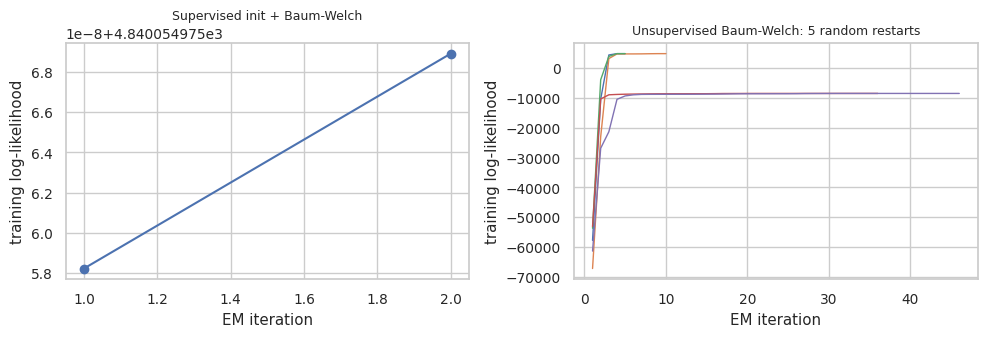

In [16]:
Xall = np.vstack(seqs); runs = []
for r in range(5):
    rr = np.random.default_rng(100 + r); mm = GaussianHMM(K)
    mm.mu = Xall[rr.choice(len(Xall), K, replace=False)].copy(); mm.var = np.tile(Xall.var(0), (K, 1))
    mm.pi = np.full(K, 1 / K); mm.A = np.full((K, K), .1 / (K - 1)) + np.eye(K) * (.9 - .1 / (K - 1))
    h = mm.baum_welch(seqs, max_iter=300, tol=1e-4); runs.append((h[-1], mm, h))
runs.sort(key=lambda x: -x[0]); ub, uh = runs[0][1], runs[0][2]
print("final training log-likelihood per restart:", [round(r[0], 1) for r in runs], "| best run iterations:", ub.n_iter_)
st = np.concatenate([ub.viterbi(s)[0] for s in seqs]); yy = np.concatenate(labs)
cont = np.zeros((K, K), int); np.add.at(cont, (st, yy), 1); mapping = cont.argmax(1)
print("state -> activity:", {i: ACT[j] for i, j in enumerate(mapping)}, "| bijective:", len(set(mapping)) == K)
for sname in ["2 unseen files", "2 unseen + multi-activity"]:
    out[("Unsupervised Baum-Welch (random init)", sname)] = evaluate(ub, SETS[sname], mapping=mapping)
fig, axs = plt.subplots(1, 2, figsize=(10, 3.5))
axs[0].plot(np.arange(1, len(hist) + 1), hist, "o-"); axs[0].set_title("Supervised init + Baum-Welch", fontsize=9)
for r in runs: axs[1].plot(np.arange(1, len(r[2]) + 1), r[2], lw=1)
axs[1].set_title("Unsupervised Baum-Welch: 5 random restarts", fontsize=9)
for a in axs: a.set_xlabel("EM iteration"); a.set_ylabel("training log-likelihood")
plt.tight_layout(); plt.savefig(FIG / "loglik_convergence.png", dpi=150); plt.show()
RES.update(unsup_ll=[round(float(r[0]), 1) for r in runs], unsup_iters=int(ub.n_iter_), unsup_bijective=bool(len(set(mapping)) == K))

## 9. Summary of results

In [17]:
summ = pd.DataFrame([{"model": k[0], "test set": k[1], "overall accuracy": round(v[2], 4)} for k, v in out.items()])
display(summ.pivot(index="model", columns="test set", values="overall accuracy"))
summ.to_csv(FIG / "model_comparison.csv", index=False)
for nm, key in [("metrics_unseen2", "2 unseen files"), ("metrics_all_heldout", "2 unseen + multi-activity")]:
    out[(main, key)][1].round(4).to_csv(FIG / f"{nm}.csv", index=False)
RES["acc"] = {f"{k[0]} | {k[1]}": round(float(v[2]), 4) for k, v in out.items()}
RES["per_file"] = {k[1]: v[3] for k, v in out.items() if k[0] == main}
RES["table_unseen2"] = out[(main, "2 unseen files")][1].round(4).to_dict("records")
RES["table_heldout"] = out[(main, "2 unseen + multi-activity")][1].round(4).to_dict("records")
RES["cm_unseen2"] = out[(main, "2 unseen files")][0].tolist(); RES["cm_heldout"] = out[(main, "2 unseen + multi-activity")][0].tolist()
RES["cm_multi"] = out[(main, "multi-activity only")][0].tolist()
np.savez(REPO / "data/hmm_params.npz", pi=bw.pi, A=bw.A, mu=bw.mu, var=bw.var, A_init=sup.A, loglik=hist)
json.dump(RES, open(FIG / "results.json", "w"), indent=1, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("saved figures/results.json")

test set,2 unseen + multi-activity,2 unseen files,multi-activity only
model,,,
Frame-wise Gaussian (no transitions),0.9264,0.9624,0.7667
Unsupervised Baum-Welch (random init),0.9202,0.9624,NaN
Viterbi + Baum-Welch (main),0.9202,0.9624,0.7333
"Viterbi, supervised init only",0.9202,0.9624,0.7333


saved figures/results.json
